# pgm_handbook — worked tour

An end-to-end tour of the package: **representation → exact inference → sampling / MCMC → Bayesian deep learning**.
Every section ends with a numerical check (`assert`) so the notebook doubles as an integration test.

Install first (from the repository root): `pip install -e ".[dev]"`

In [1]:
import math, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.grid": True, "grid.alpha": .3})

import pgm_handbook
print("pgm_handbook", pgm_handbook.__version__)

pgm_handbook 0.1.0


## 1. Bayesian networks — the burglary / alarm network

$P(B,E,A,J,M)=P(B)P(E)P(A\mid B,E)P(J\mid A)P(M\mid A)$

In [2]:
from pgm_handbook.representation import BayesianNetwork, TabularCPD

bn = BayesianNetwork()
for n in ("Burglary", "Earthquake", "Alarm", "JohnCalls", "MaryCalls"):
    bn.add_node(n)
for parent, child in [("Burglary", "Alarm"), ("Earthquake", "Alarm"),
                      ("Alarm", "JohnCalls"), ("Alarm", "MaryCalls")]:
    bn.add_edge(parent, child)

bn.set_cpd(TabularCPD("Burglary", (), {(): {True: 0.001, False: 0.999}}))
bn.set_cpd(TabularCPD("Earthquake", (), {(): {True: 0.002, False: 0.998}}))
bn.set_cpd(TabularCPD("Alarm", ("Burglary", "Earthquake"), {
    (True, True):   {True: 0.95,  False: 0.05},
    (True, False):  {True: 0.94,  False: 0.06},
    (False, True):  {True: 0.29,  False: 0.71},
    (False, False): {True: 0.001, False: 0.999}}))
bn.set_cpd(TabularCPD("JohnCalls", ("Alarm",), {
    (True,): {True: 0.90, False: 0.10}, (False,): {True: 0.05, False: 0.95}}))
bn.set_cpd(TabularCPD("MaryCalls", ("Alarm",), {
    (True,): {True: 0.70, False: 0.30}, (False,): {True: 0.01, False: 0.99}}))

print("nodes:", bn.nodes())
print("edges:", bn.edges())

# the joint is a product of CPDs and sums to 1
total = sum(bn.joint_probability(dict(zip(bn.nodes(), v)))
            for v in itertools.product([True, False], repeat=5))
print("sum of joint =", total)
assert math.isclose(total, 1.0)

nodes: ['Burglary', 'Earthquake', 'Alarm', 'JohnCalls', 'MaryCalls']
edges: [('Burglary', 'Alarm'), ('Earthquake', 'Alarm'), ('Alarm', 'JohnCalls'), ('Alarm', 'MaryCalls')]
sum of joint = 0.9999999999999999


### Exact inference: enumeration vs. variable elimination

In [3]:
from pgm_handbook.inference import enumeration_ask, variable_elimination

evidence = {"JohnCalls": True, "MaryCalls": True}
p_enum = enumeration_ask("Burglary", evidence, bn)
p_ve   = variable_elimination("Burglary", evidence, bn)
print("enumeration:", p_enum)
print("var. elim. :", p_ve)

assert abs(p_enum[True] - 0.284) < 1e-3          # textbook value
assert all(math.isclose(p_enum[k], p_ve[k], rel_tol=1e-9) for k in p_enum)

enumeration: {False: 0.7158281646356071, True: 0.28417183536439294}
var. elim. : {False: 0.7158281646356071, True: 0.284171835364393}


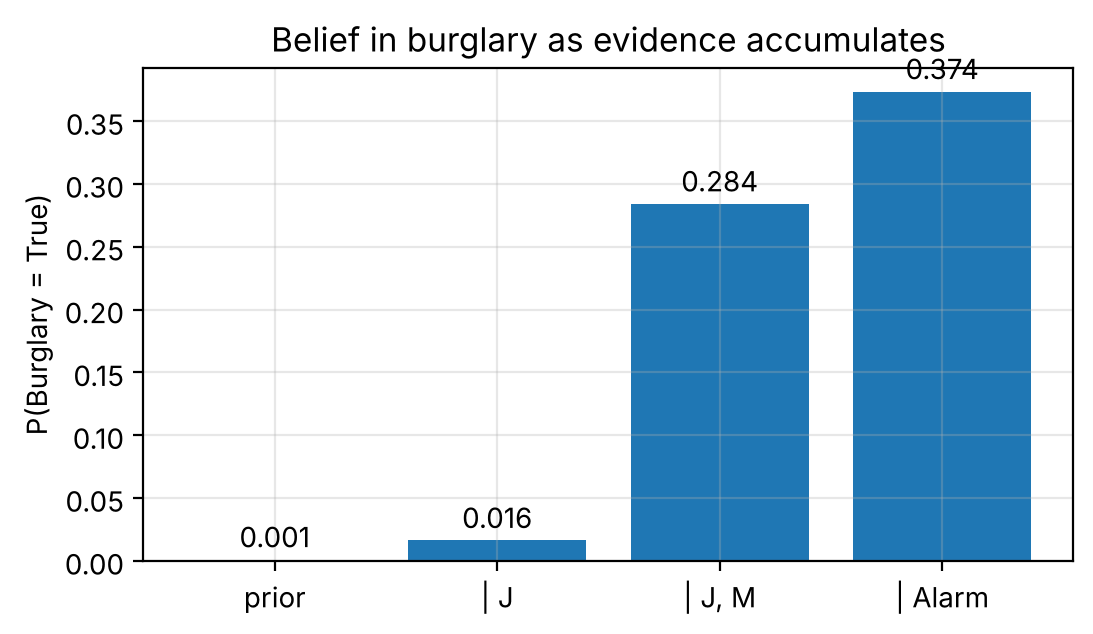

In [4]:
fig, ax = plt.subplots()
labels = ["prior", "| J", "| J, M", "| Alarm"]
vals = [enumeration_ask("Burglary", {}, bn)[True],
        enumeration_ask("Burglary", {"JohnCalls": True}, bn)[True],
        p_enum[True],
        enumeration_ask("Burglary", {"Alarm": True}, bn)[True]]
ax.bar(labels, vals, color="tab:blue")
for i, v in enumerate(vals): ax.text(i, v + .01, f"{v:.3f}", ha="center")
ax.set_ylabel("P(Burglary = True)"); ax.set_title("Belief in burglary as evidence accumulates")
plt.show()

### d-separation and explaining away

In [5]:
print("J ⟂ M | Alarm :", bn.is_d_separated(["JohnCalls"], ["MaryCalls"], ["Alarm"]))
print("J ⟂ M         :", bn.is_d_separated(["JohnCalls"], ["MaryCalls"], []))
print("B ⟂ E         :", bn.is_d_separated(["Burglary"], ["Earthquake"], []))
print("B ⟂ E | Alarm :", bn.is_d_separated(["Burglary"], ["Earthquake"], ["Alarm"]))
assert bn.is_d_separated(["JohnCalls"], ["MaryCalls"], ["Alarm"])
assert not bn.is_d_separated(["Burglary"], ["Earthquake"], ["Alarm"])   # v-structure opens

# explaining away: learning of an earthquake lowers belief in a burglary
b_a  = enumeration_ask("Burglary", {"Alarm": True}, bn)[True]
b_ae = enumeration_ask("Burglary", {"Alarm": True, "Earthquake": True}, bn)[True]
print(f"P(B | A) = {b_a:.4f}   P(B | A, E) = {b_ae:.4f}")
assert b_ae < b_a

J ⟂ M | Alarm : True
J ⟂ M         : False
B ⟂ E         : True
B ⟂ E | Alarm : False
P(B | A) = 0.3736   P(B | A, E) = 0.0033


## 2. Markov networks — clique potentials and the partition function

A 3-variable chain $A - B - C$ with "agreement-favouring" potentials.

maximal cliques: [('B', 'C'), ('A', 'B')]
Z = 242.0
most probable configuration: (0, 0, 0) with p = 0.4132


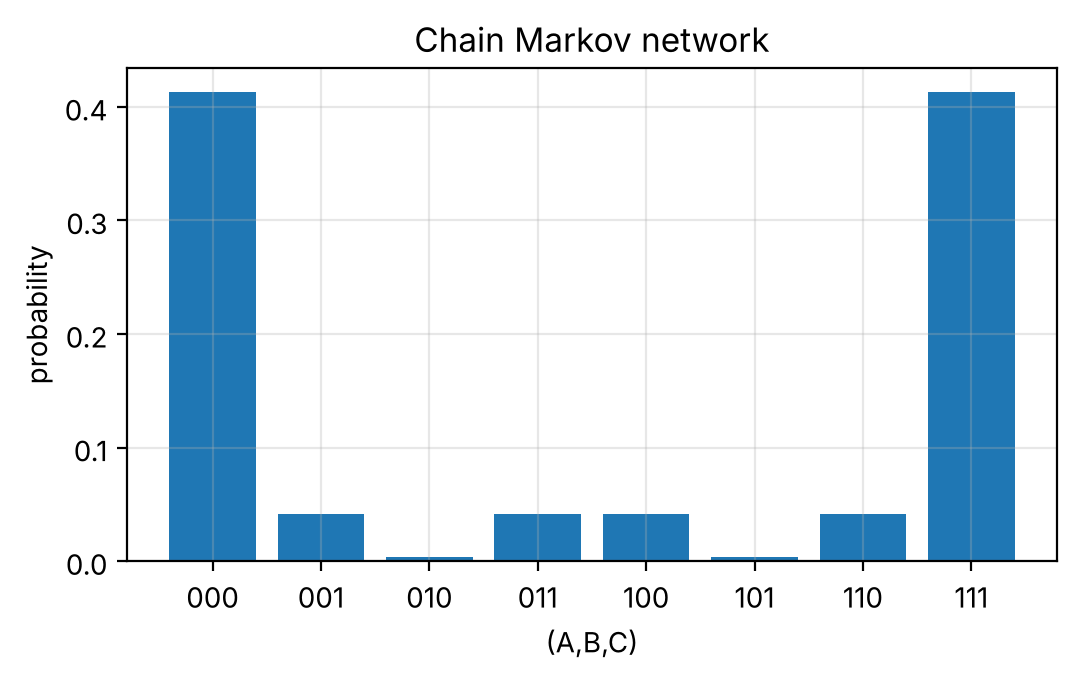

In [6]:
from pgm_handbook.representation import MarkovNetwork

agree = {(0, 0): 10.0, (0, 1): 1.0, (1, 0): 1.0, (1, 1): 10.0}
mn = MarkovNetwork()
mn.add_factor(("A", "B"), agree)
mn.add_factor(("B", "C"), agree)

domains = {v: [0, 1] for v in "ABC"}
Z = mn.partition_function(domains)
print("maximal cliques:", mn.maximal_cliques())
print("Z =", Z)
assert math.isclose(Z, 2 * (10 + 1) ** 2)       # by hand: for each b, (sum_a phi(a,b))^2 = 11^2 -> Z = 242

probs = {s: mn.unnormalized_probability(dict(zip("ABC", s))) / Z
         for s in itertools.product([0, 1], repeat=3)}
assert math.isclose(sum(probs.values()), 1.0)
best = max(probs, key=probs.get)
print("most probable configuration:", best, "with p =", round(probs[best], 4))

fig, ax = plt.subplots()
ax.bar(["".join(map(str, s)) for s in probs], list(probs.values()))
ax.set_xlabel("(A,B,C)"); ax.set_ylabel("probability"); ax.set_title("Chain Markov network")
plt.show()

## 3. Local CPD structures

Deterministic AND: {True: 1.0, False: 0.0}
Multiplexer (Sel=1 -> B='y'): {'x': 0.0, 'y': 1.0, 'z': 0.0}
Noisy-OR  Flu=False Cold=False  P(Fever)=0.0100
Noisy-OR  Flu=False Cold=True   P(Fever)=0.4060
Noisy-OR  Flu=True  Cold=False  P(Fever)=0.9505
Noisy-OR  Flu=True  Cold=True   P(Fever)=0.9703


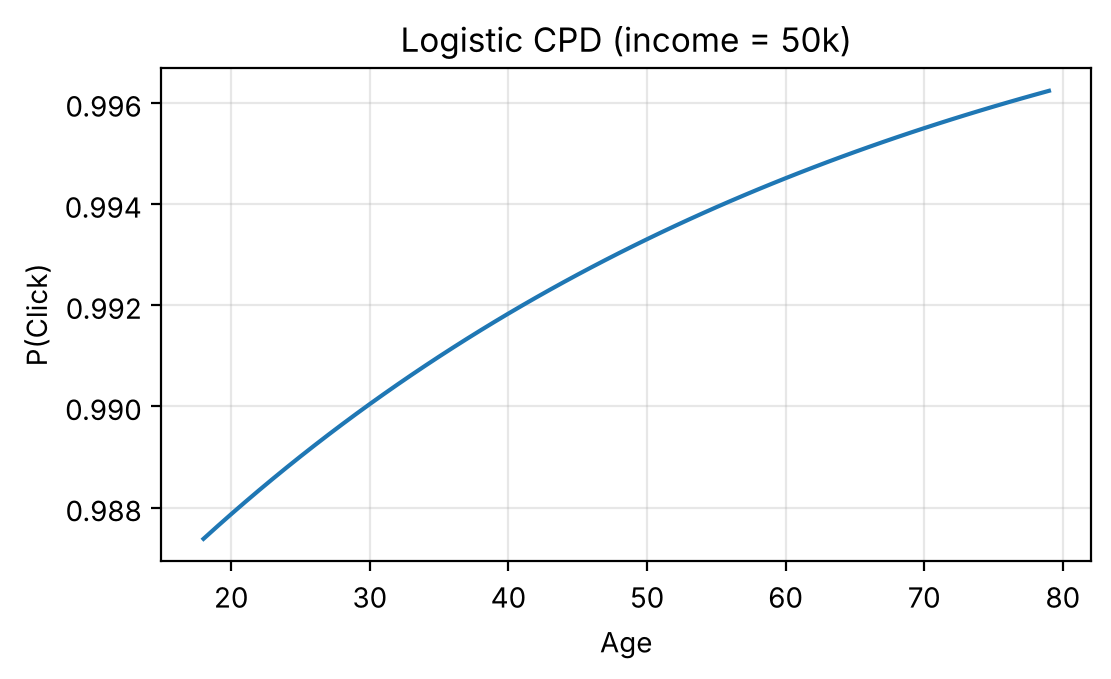

Linear-Gaussian  mean = 19.998  var = 0.248


In [7]:
from pgm_handbook.representation import (DeterministicCPD, MultiplexerCPD, NoisyORCPD,
                                         NoisyMAXCPD, LogisticCPD, LinearGaussianCPD)

det = DeterministicCPD(variable="Out", parents=("A", "B"), func=lambda a, b: a and b)
print("Deterministic AND:", {v: det.prob(v, (True, True)) for v in (True, False)})

mux = MultiplexerCPD(variable="Out", selector="Sel", choices=("A", "B", "C"), domain=["x", "y", "z"])
print("Multiplexer (Sel=1 -> B='y'):", {v: mux.prob(v, (1, "x", "y", "z")) for v in "xyz"})

nor = NoisyORCPD(variable="Fever", parents=("Flu", "Cold"), q=(0.95, 0.4), leak=0.01)
rows = [(f, c, nor.prob(True, (f, c))) for f in (False, True) for c in (False, True)]
for f, c, p in rows: print(f"Noisy-OR  Flu={f!s:5} Cold={c!s:5}  P(Fever)={p:.4f}")
# noisy-OR closed form: 1 - (1-leak) * prod(1 - q_i for active parents)
assert math.isclose(nor.prob(True, (True, True)), 1 - 0.99 * 0.05 * 0.6)

logit = LogisticCPD(variable="Click", parents=("Age", "Income"), weights=(0.02, 0.0001), bias=-1.0)
ages = np.arange(18, 80)
plt.plot(ages, [logit.prob(True, (a, 50_000)) for a in ages])
plt.xlabel("Age"); plt.ylabel("P(Click)"); plt.title("Logistic CPD (income = 50k)"); plt.show()

lg = LinearGaussianCPD(variable="Sensor", parents=("Temp",), weights=(1.0,), bias=0.0, variance=0.25)
rng = np.random.default_rng(0)
s = np.array([lg.sample((20.0,), rng) for _ in range(5000)])
print("Linear-Gaussian  mean =", round(s.mean(), 3), " var =", round(s.var(), 3))
assert abs(s.mean() - 20) < .05 and abs(s.var() - .25) < .03

## 4. Template models

### 4a. Plate model — replicate a student template

In [8]:
from pgm_handbook.representation import PlateModel

grade_table = {(0, 0): {0: .3, 1: .4, 2: .3},  (0, 1): {0: .05, 1: .25, 2: .7},
               (1, 0): {0: .9, 1: .08, 2: .02}, (1, 1): {0: .5, 1: .3, 2: .2}}
plate = PlateModel(index_name="i", index_values=[0, 1, 2])
plate.add_template("Int_{i}",  (), lambda n, _: TabularCPD(n, (), {(): {0: .7, 1: .3}}))
plate.add_template("Diff_{i}", (), lambda n, _: TabularCPD(n, (), {(): {0: .4, 1: .6}}))
plate.add_template("Grade_{i}", ("Int_{i}", "Diff_{i}"), lambda n, pa: TabularCPD(n, pa, grade_table))

students = plate.ground()
print(len(students.nodes()), "nodes,", len(students.edges()), "edges")
assert (len(students.nodes()), len(students.edges())) == (9, 6)
# students are independent of one another (different plates)
assert students.is_d_separated(["Grade_0"], ["Grade_1"], [])
print("P(Grade_0 | Int_0 = 1):", enumeration_ask("Grade_0", {"Int_0": 1}, students))

9 nodes, 6 edges
P(Grade_0 | Int_0 = 1): {0: 0.6600000000000001, 1: 0.21199999999999988, 2: 0.12799999999999997}


### 4b. Dynamic Bayesian network — HMM filtering / smoothing

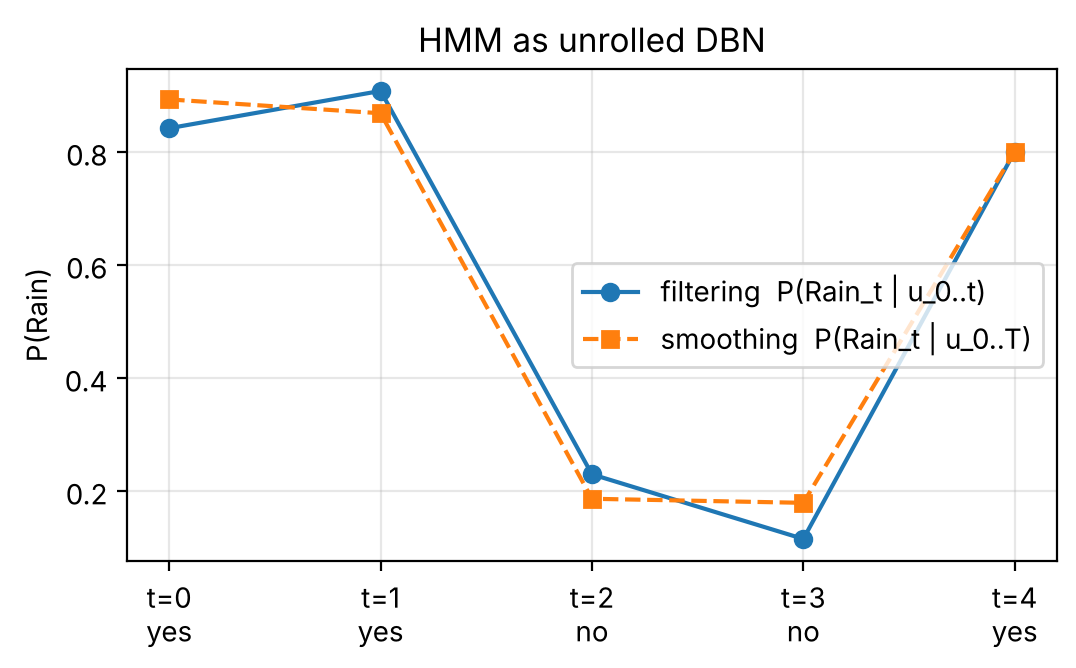

In [9]:
from pgm_handbook.representation import DynamicBayesianNetwork

dbn = DynamicBayesianNetwork(state_vars=["Weather"])
dbn.set_initial(TabularCPD("Weather", (), {(): {"Sun": .6, "Rain": .4}}))
dbn.set_transition(TabularCPD("Weather", ("Weather",),
                              {("Sun",): {"Sun": .7, "Rain": .3}, ("Rain",): {"Sun": .4, "Rain": .6}}))
dbn.add_observation("Umbrella", TabularCPD("Umbrella", ("Weather",),
                    {("Sun",): {"yes": .1, "no": .9}, ("Rain",): {"yes": .8, "no": .2}}))

T = 5
hmm = dbn.unroll(T)
obs = ["yes", "yes", "no", "no", "yes"]
evidence = {f"Umbrella_{t}": o for t, o in enumerate(obs)}

filtered = [enumeration_ask(f"Weather_{t}", {f"Umbrella_{k}": obs[k] for k in range(t + 1)}, hmm)["Rain"]
            for t in range(T)]
smoothed = [variable_elimination(f"Weather_{t}", evidence, hmm)["Rain"] for t in range(T)]

plt.plot(filtered, "o-", label="filtering  P(Rain_t | u_0..t)")
plt.plot(smoothed, "s--", label="smoothing  P(Rain_t | u_0..T)")
plt.xticks(range(T), [f"t={t}\n{o}" for t, o in enumerate(obs)])
plt.ylabel("P(Rain)"); plt.legend(); plt.title("HMM as unrolled DBN"); plt.show()
assert filtered[0] > .4 and filtered[2] < filtered[1]       # no umbrella -> rain belief drops

## 5. Monte-Carlo and MCMC

### 5a. Importance sampling — $E[X^2]$ under $N(0,1)$ with proposal $N(1,2^2)$

In [10]:
from pgm_handbook.inference import (importance_sampling, self_normalized_importance_sampling,
                                    inverse_transform_sample, inverse_transform_sample_discrete,
                                    rejection_sample, rejection_sample_box,
                                    metropolis_hastings, gibbs_sampler)

target   = lambda x: math.exp(-0.5 * x ** 2)
proposal = lambda x: math.exp(-0.5 * ((x - 1) / 2) ** 2) / 2
draw     = lambda rng: float(rng.normal(1, 2))

rng = np.random.default_rng(0)
xs, ws = self_normalized_importance_sampling(target, proposal, draw, 100_000, rng)
est = float(np.sum(np.asarray(ws) * np.square(xs)))        # weights already sum to 1
print("E[X^2] ≈", round(est, 4), "(exact 1.0)")
assert abs(est - 1) < .05

E[X^2] ≈ 0.997 (exact 1.0)


### 5b. Inverse-transform sampling

Exp mean: 0.4984 (0.5)   die: {'A': 0.10034, 'B': 0.20168, 'C': 0.30306, 'D': 0.39492}


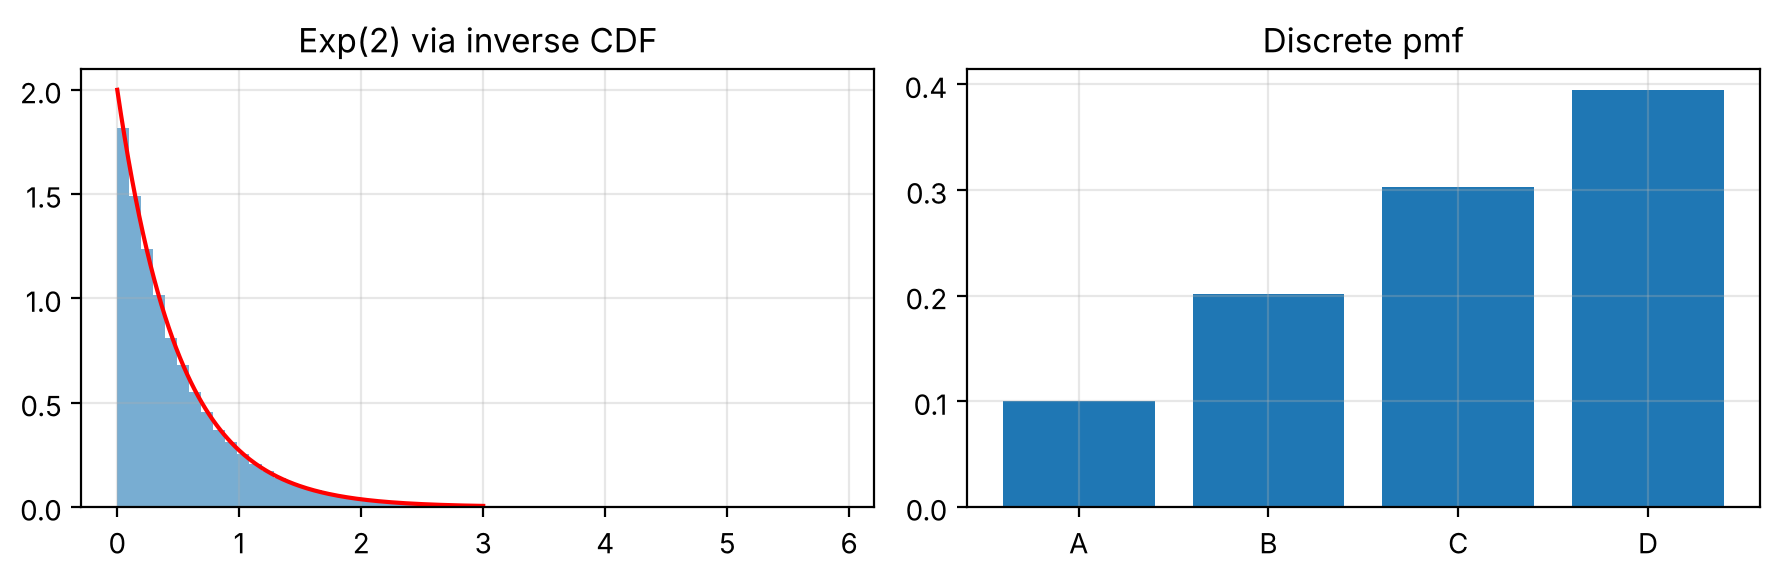

In [11]:
rate = 2.0
exp_s = inverse_transform_sample(lambda u: -math.log(1 - u) / rate, 50_000)
pmf = {"A": .1, "B": .2, "C": .3, "D": .4}
die = inverse_transform_sample_discrete(pmf, 50_000)
emp = {k: die.count(k) / len(die) for k in pmf}
print("Exp mean:", round(float(exp_s.mean()), 4), "(0.5)   die:", emp)
assert abs(exp_s.mean() - .5) < .02 and all(abs(emp[k] - pmf[k]) < .01 for k in pmf)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(exp_s, 60, density=True, alpha=.6); g = np.linspace(0, 3, 200)
ax[0].plot(g, rate * np.exp(-rate * g), "r"); ax[0].set_title("Exp(2) via inverse CDF")
ax[1].bar(emp.keys(), emp.values()); ax[1].set_title("Discrete pmf"); plt.tight_layout(); plt.show()

### 5c. Rejection sampling — truncated normal on $[-1,1]$

Envelope variant: $\tilde p(x)\le M\,q(x)$.  Box variant: `M` bounds $\tilde p$ on the box.

acceptance: envelope 0.854, box 0.856  (theory 0.856)
variance  : envelope 0.2896, box 0.2890  (theory 0.2911)


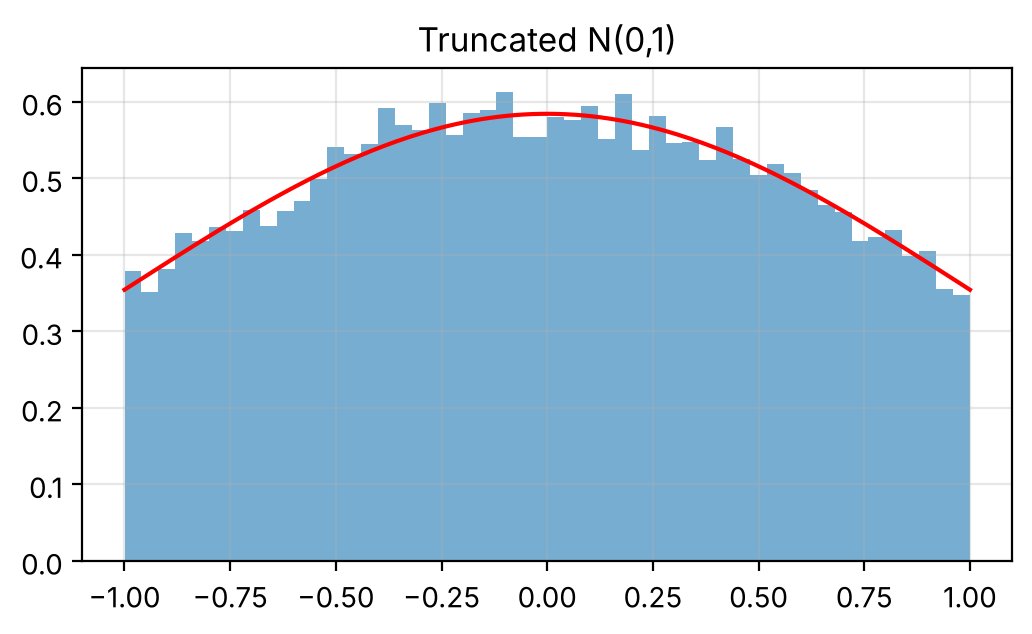

In [12]:
trunc = lambda x: math.exp(-0.5 * x * x) if -1 <= x <= 1 else 0.0
rng = np.random.default_rng(1)
acc, total = rejection_sample(trunc, lambda x: .5, lambda r: float(r.uniform(-1, 1)), M=2.0,
                              n_samples=30_000, rng=rng)
box, total_b = rejection_sample_box(lambda x: trunc(float(x[0])), [-1.0], [1.0], M=1.0,
                                    n_samples=30_000, rng=rng)
box = np.array([b[0] for b in box])
theory_var = 1 - 2 * stats.norm.pdf(1) / (2 * stats.norm.cdf(1) - 1)
print(f"acceptance: envelope {len(acc)/total:.3f}, box {len(box)/total_b:.3f}  (theory 0.856)")
print(f"variance  : envelope {np.var(acc):.4f}, box {box.var():.4f}  (theory {theory_var:.4f})")
assert abs(np.var(acc) - theory_var) < .01 and abs(box.var() - theory_var) < .01
plt.hist(acc, 50, density=True, alpha=.6)
g = np.linspace(-1, 1, 200); plt.plot(g, np.exp(-g**2/2) / 1.7112, "r"); plt.title("Truncated N(0,1)"); plt.show()

### 5d. Metropolis–Hastings on a bimodal target

P(x>0) = 0.478 (0.5)


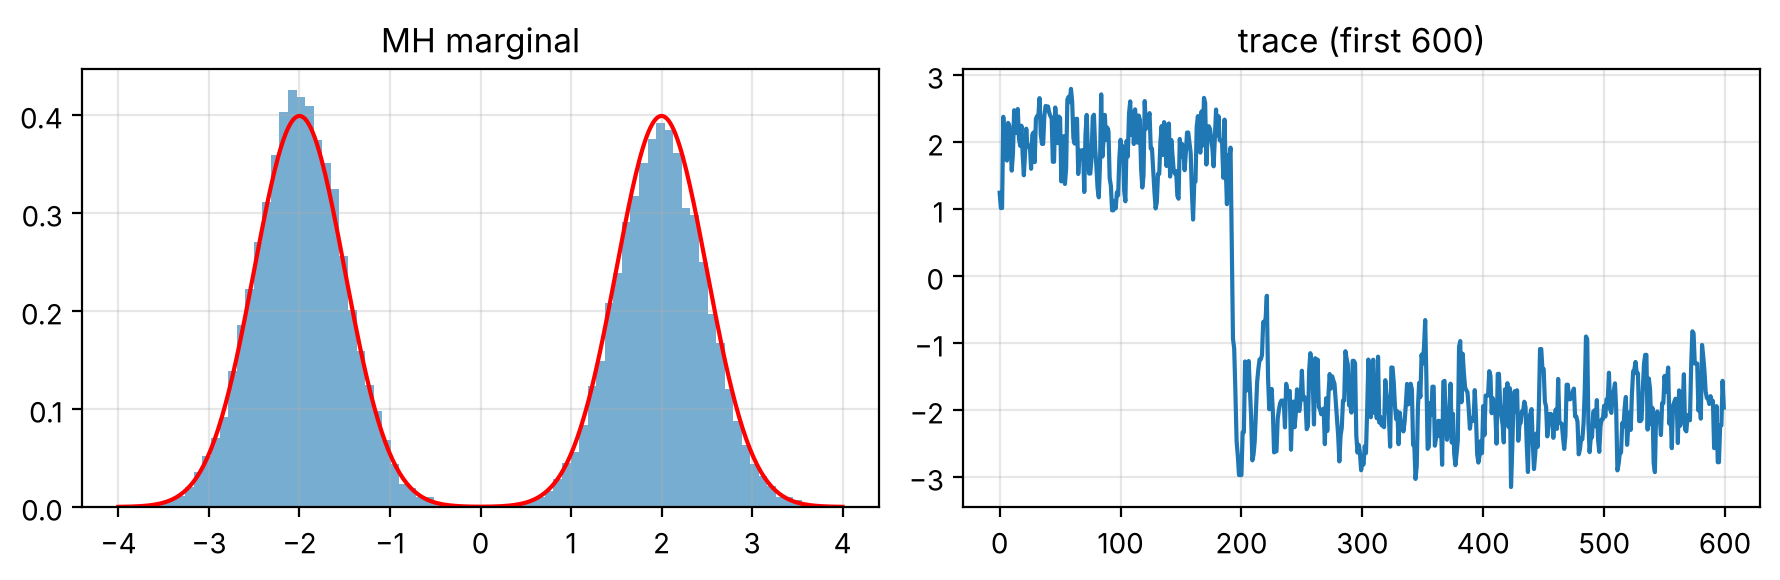

In [13]:
mix = lambda x: .5*math.exp(-.5*((x+2)/.5)**2) + .5*math.exp(-.5*((x-2)/.5)**2)
chain = np.asarray(metropolis_hastings(
    mix, lambda x, r: float(x + r.normal(0, .5)), lambda new, old: math.exp(-.5*((new-old)/.5)**2),
    x0=0.0, n_samples=40_000, burn_in=1_000, thin=2, rng=np.random.default_rng(123)))
print("P(x>0) =", round(float((chain > 0).mean()), 3), "(0.5)")
assert abs((chain > 0).mean() - .5) < .03

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(chain, 80, density=True, alpha=.6)
g = np.linspace(-4, 4, 400)
ax[0].plot(g, .5*stats.norm.pdf(g, -2, .5) + .5*stats.norm.pdf(g, 2, .5), "r"); ax[0].set_title("MH marginal")
ax[1].plot(chain[:600]); ax[1].set_title("trace (first 600)"); plt.tight_layout(); plt.show()

### 5e. Gibbs sampling — correlated bivariate Gaussian

sample rho = 0.7 (theory 0.7)


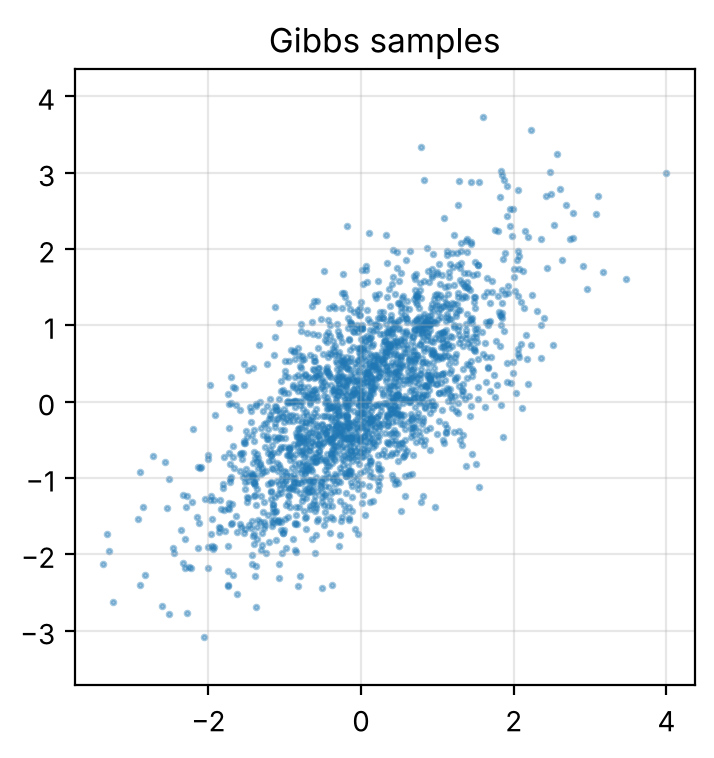

In [14]:
rho = .7; s = math.sqrt(1 - rho**2)
gchain = gibbs_sampler({"x": lambda st, r: float(r.normal(rho*st["y"], s)),
                        "y": lambda st, r: float(r.normal(rho*st["x"], s))},
                       x0={"x": 0., "y": 0.}, n_samples=20_000, burn_in=500, thin=2,
                       rng=np.random.default_rng(0))
gx = np.array([c["x"] for c in gchain]); gy = np.array([c["y"] for c in gchain])
print("sample rho =", round(float(np.corrcoef(gx, gy)[0, 1]), 3), f"(theory {rho})")
assert abs(np.corrcoef(gx, gy)[0, 1] - rho) < .05
plt.figure(figsize=(4, 4)); plt.scatter(gx[::10], gy[::10], s=3, alpha=.4); plt.axis("equal"); plt.title("Gibbs samples"); plt.show()

## 6. Bayesian neural networks with SGLD

SGLD update: $\theta_{t+1}=\theta_t+\tfrac{\epsilon}{2}\nabla\log p(\theta\mid D)+\mathcal N(0,\epsilon)$.
We do a short MAP warm-up (burn-in shortcut), then collect SGLD samples of the weights and form the predictive
posterior, splitting **epistemic** (weight) from **aleatoric** (observation-noise) uncertainty.

In [15]:
import torch
from pgm_handbook.deep_bayes import (BayesianMLP, GaussianPrior, sgld_posterior_samples, ensemble_predict)

torch.manual_seed(0)
n, noise_std = 128, 0.1
x_train = torch.empty(n, 1).uniform_(-3, 3)
y_train = torch.sin(x_train) + noise_std * torch.randn(n, 1)

model = BayesianMLP(1, [16, 16], 1, prior=GaussianPrior(0.0, 1.0))
mu = [p for k, p in model.named_parameters() if k.endswith("_mu")]       # SGLD over weight means
for k, p in model.named_parameters():
    if not k.endswith("_mu"): p.requires_grad_(False)

def neg_log_lik(idx=None):
    xb, yb = (x_train, y_train) if idx is None else (x_train[idx], y_train[idx])
    return 0.5 * ((model.forward_mean(xb) - yb) ** 2).sum() / noise_std**2 * (n / xb.size(0))

adam = torch.optim.Adam(mu, lr=1e-2)                                     # MAP warm-up
for _ in range(1500):
    adam.zero_grad()
    ((neg_log_lik() + 0.5 * sum((p**2).sum() for p in mu)) / n).backward()
    adam.step()

snaps = sgld_posterior_samples(mu, lambda: neg_log_lik(torch.randperm(n)[:32]),
                               n_steps=6000, lr=3e-6, prior_precision=1.0, burn_in=2000, thin=20)
print(len(snaps), "posterior samples")

200 posterior samples


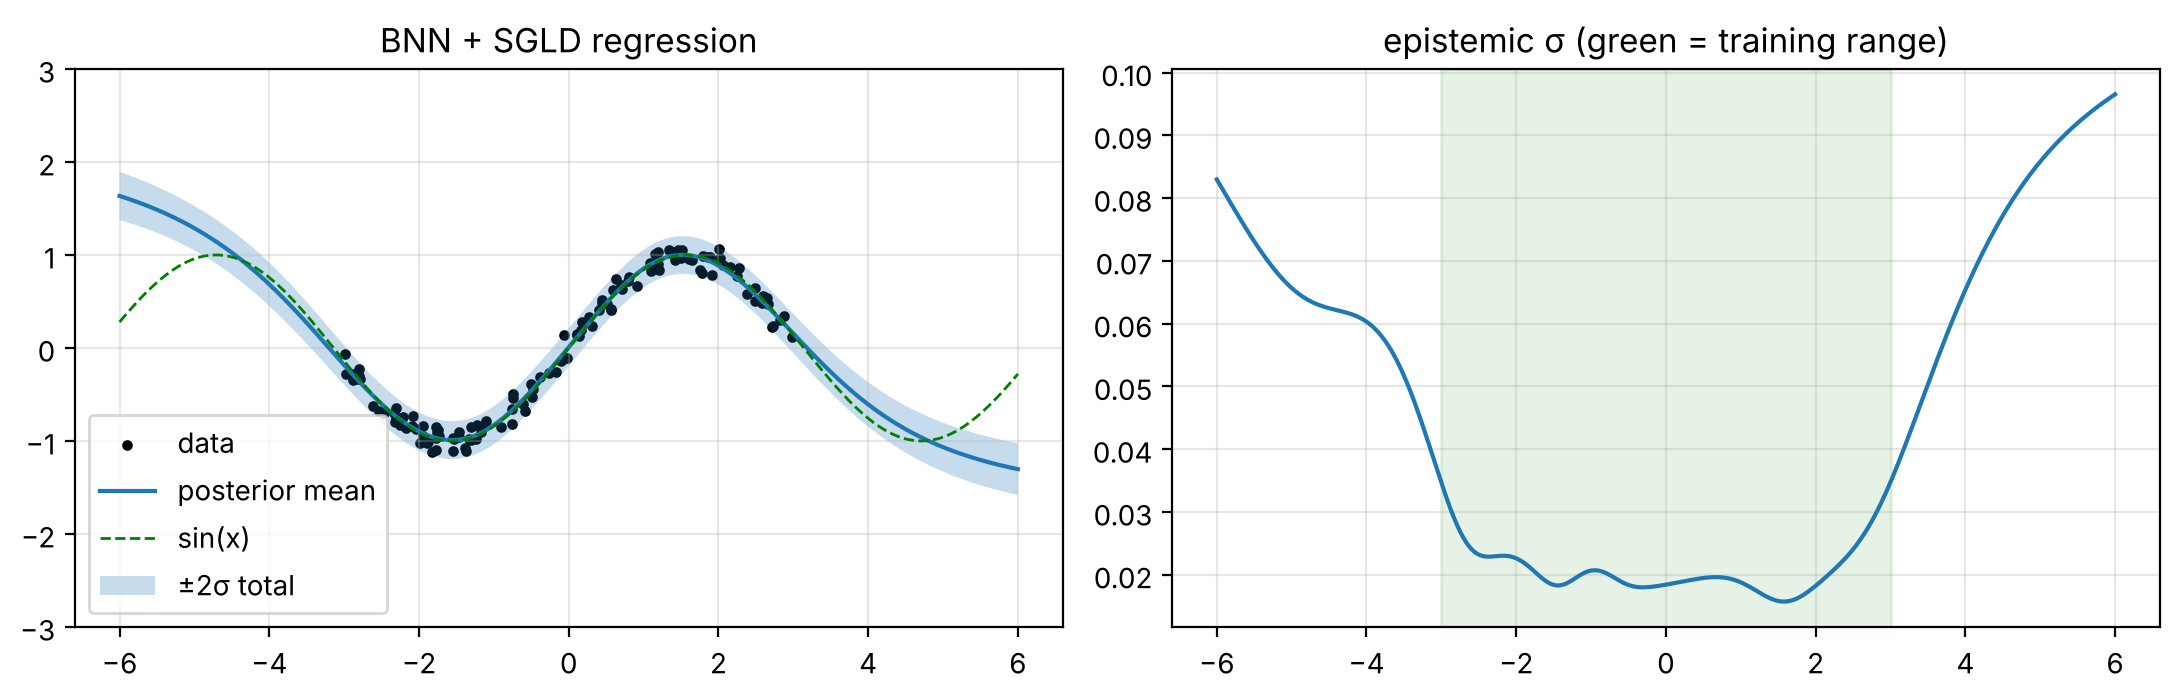

epistemic σ inside=0.019  far outside=0.083   RMSE on [-3,3]=0.016


In [16]:
grid = torch.linspace(-6, 6, 300).unsqueeze(-1)
out = ensemble_predict(model.forward_mean, mu, snaps, grid, noise_std)
m, epi, tot = (out[k].squeeze() .numpy() for k in ("mean", "epistemic_std", "total_std"))
g = grid.squeeze().numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(x_train, y_train, s=8, c="k", label="data")
ax[0].plot(g, m, "tab:blue", label="posterior mean"); ax[0].plot(g, np.sin(g), "g--", lw=1, label="sin(x)")
ax[0].fill_between(g, m - 2*tot, m + 2*tot, alpha=.25, label="±2σ total")
ax[0].set_ylim(-3, 3); ax[0].legend(loc="lower left"); ax[0].set_title("BNN + SGLD regression")
ax[1].plot(g, epi); ax[1].axvspan(-3, 3, alpha=.1, color="g"); ax[1].set_title("epistemic σ (green = training range)")
plt.tight_layout(); plt.show()

inside, outside = epi[np.abs(g) < 1].mean(), epi[np.abs(g) > 5].mean()
rmse = float(np.sqrt(np.mean((m[np.abs(g) <= 3] - np.sin(g[np.abs(g) <= 3]))**2)))
print(f"epistemic σ inside={inside:.3f}  far outside={outside:.3f}   RMSE on [-3,3]={rmse:.3f}")
assert outside > inside and rmse < .15

### Dynamic (recurrent) Bayesian network

In [17]:
from pgm_handbook.deep_bayes import DynamicBNN

torch.manual_seed(0)
dyn = DynamicBNN(in_features=2, hidden_size=8, out_features=1)
x_seq = torch.randn(4, 5, 2)                         # (batch, time, features)
print("one sampled pass :", tuple(dyn(x_seq).shape))
pred = dyn.predictive(x_seq, n_samples=30)
print({k: tuple(v.shape) for k, v in pred.items()})
print("KL(q || prior) =", float(dyn.kl_divergence().detach()))
assert pred["mean"].shape == (4, 5, 1) and float(dyn.kl_divergence().detach()) >= 0

one sampled pass : (4, 5, 1)
{'mean': (4, 5, 1), 'epistemic_std': (4, 5, 1), 'aleatoric_std': (4, 5, 1), 'total_std': (4, 5, 1)}
KL(q || prior) = 244.1758270263672


---
**Done.** All assertions above passed: textbook posterior 0.284, enumeration ≡ variable elimination, d-separation, noisy-OR closed form,
sampler moments vs theory, and SGLD uncertainty that grows outside the data.